# 05 인과분석: 추천 위쪽에 뜨면 실제로 더 많이 갈까?

> ⚠️ 이 노트북의 직원·방문 데이터는 모두 **가상**이에요. 식당 목록과 별점만 실제(카카오·구글)예요.
> 정답 효과를 미리 정해 두고, 어떤 분석 방법이 그 정답을 맞히는지 **방법을 검증**하는 것이 목적이에요.

**질문:** 식당이 추천 화면 1~3위에 뜨면(처치), 그 식당에 갈 확률(결과)이 얼마나 오르나?

**왜 어려운가 (인과 그림)**
```
 별점·거리 (혼란변수) ──→ 1~3위에 뜸 (처치)
        │                        │
        └──────────→ 방문 (결과) ←┘
```
별점이 높고 가까운 식당은 ① 추천 위쪽에 잘 뜨고 ② 원래도 사람들이 많이 가요.
그래서 그냥 비교하면 **별점 효과가 추천 효과에 섞여** 실제보다 커 보여요.

## 0. 준비
`restaurants_with_keywords.csv`가 이 노트북과 같은 폴더(또는 `data/`)에 있어야 해요. Colab이면 왼쪽 📁에 올리세요.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression

SEED = 42            # 같은 숫자면 언제 실행해도 같은 결과(재현성)
TRUE_EFFECT = 0.05   # 🎯 정답: 1~3위에 뜨면 방문 확률 +5%p (우리가 정한 값)
rng = np.random.default_rng(SEED)

path = next(p for p in ['restaurants_with_keywords.csv', 'data/restaurants_with_keywords.csv', '../app/data/restaurants_with_keywords.csv', 'app/data/restaurants_with_keywords.csv'] if os.path.exists(p))
rest = pd.read_csv(path)

## 1. 가상 데이터 만들기
- 점심 후보: 걸어서 10분 이내 식사 장소(실제 목록)
- 가상 직원 100명 = 20개 팀 × 5명. 팀원끼리 같이 밥 먹는다고 가정해서 **팀 단위**로 기록해요.
- 60일(약 3달) 동안 팀마다 매일 그날 고른 조건(메뉴 등)에 맞는 후보 30곳 중 추천 10곳을 보고, 각 식당에 갈지 말지가 정해져요.
- **A/B 실험:** 10개 팀(B)은 추천 10곳의 순서를 무작위로 섞어서 보여 줘요. 나머지 10개 팀(A)은 평소처럼 점수 순서.

In [2]:
NOT_MEAL = {'간식', '식품판매', '구내식당', '푸드코트', '술집'}
cand = rest[(rest['walk_min'] <= 10) & ~rest['menu_category'].isin(NOT_MEAL)].copy()
cand['rating'] = cand['google_rating'].fillna(cand['google_rating'].mean())   # 별점 모름 → 평균
cand['quality'] = (cand['rating'] - cand['rating'].mean()) / cand['rating'].std()  # 표준화(평균 0)
cand = cand[['restaurant_id', 'name', 'rating', 'quality', 'walk_min']].reset_index(drop=True)

TEAMS = [f'T{i:02d}' for i in range(1, 21)]
SHUFFLE_TEAMS = set(rng.choice(TEAMS, 10, replace=False))   # 무작위로 B팀 10개 고르기
team_taste = dict(zip(TEAMS, rng.normal(0, 0.01, len(TEAMS))))  # 팀마다 외식 성향이 조금씩 다름

rows = []
for day in range(1, 61):
    for team in TEAMS:
        # 그날 팀이 고른 조건에 맞는 후보 30곳(메뉴·예산 등을 고른 것을 무작위 30곳으로 흉내)
        pool = cand.sample(30, random_state=int(rng.integers(1e9))).copy()
        # 추천 점수 = 별점·거리 + 그때그때 바뀌는 부분(동료 리뷰·목적 가산점 등)
        pool['rec_score'] = pool['quality'] - 0.1 * pool['walk_min'] + rng.normal(0, 0.7, len(pool))
        top10 = pool.nlargest(10, 'rec_score')
        shown = top10.sample(frac=1, random_state=int(rng.integers(1e9))) if team in SHUFFLE_TEAMS else top10
        for rank, (_, r) in enumerate(shown.iterrows(), start=1):
            top3 = int(rank <= 3)
            # 방문 확률 = 기본(별점↑, 거리↓, 팀 성향) + 정답 효과 × 1~3위 여부
            p_base = np.clip(0.10 + 0.05 * r['quality'] - 0.008 * r['walk_min'] + team_taste[team], 0.01, 0.6)
            p = p_base + TRUE_EFFECT * top3
            rows.append({'day': day, 'team': team, 'group': 'B(섞음)' if team in SHUFFLE_TEAMS else 'A(평소)',
                         'restaurant_id': r['restaurant_id'], 'rank': rank, 'top3': top3,
                         'quality': r['quality'], 'walk_min': r['walk_min'],
                         'visit': int(rng.random() < p), 'data_type': '가상'})
sim = pd.DataFrame(rows)
print(f'가상 기록 {len(sim):,}줄 (60일 × 20팀 × 추천 10곳), 후보 식당 {len(cand)}곳')
print('B팀(순서 섞음):', ', '.join(sorted(SHUFFLE_TEAMS)))
sim.head()

가상 기록 12,000줄 (60일 × 20팀 × 추천 10곳), 후보 식당 804곳
B팀(순서 섞음): T01, T02, T04, T07, T09, T10, T13, T14, T15, T20


,day,team,group,restaurant_id,rank,top3,quality,walk_min,visit,data_type
0,1,T01,B(섞음),K1170879648,1,1,1.776991,6,0,가상
1,1,T01,B(섞음),K1310992699,2,1,1.547217,2,0,가상
2,1,T01,B(섞음),K1440816395,3,1,1.547217,7,0,가상
3,1,T01,B(섞음),K1915458980,4,0,1.776991,7,0,가상
4,1,T01,B(섞음),K1280094557,5,0,0.857895,2,0,가상


## 2. 방법 ① 단순 비교 (틀린 방법)
A팀(평소 순서)에서 1~3위 식당 방문율 − 4~10위 식당 방문율.

In [3]:
A = sim[sim['group'] == 'A(평소)']
naive = A.loc[A.top3 == 1, 'visit'].mean() - A.loc[A.top3 == 0, 'visit'].mean()
print(f'단순 비교: {naive:+.3f}  (정답 {TRUE_EFFECT:+.3f})')
print('1~3위 식당의 평균 별점(표준화):', round(A.loc[A.top3 == 1, 'quality'].mean(), 2),
      '/ 4~10위:', round(A.loc[A.top3 == 0, 'quality'].mean(), 2))

단순 비교: +0.078  (정답 +0.050)
1~3위 식당의 평균 별점(표준화): 1.25 / 4~10위: 0.56


1~3위 식당이 원래 별점도 높아서, 별점 효과가 섞여 정답보다 크게 나와요.

## 3. 방법 ② 팀 단위 A/B 실험 (가장 믿을 만한 방법)
B팀은 순서를 무작위로 섞었기 때문에 1~3위에 뜬 식당과 4~10위 식당의 별점이 평균적으로 같아요.
그래서 차이는 **순위 자체의 효과**만 남아요.
팀원끼리 같이 다니니(서로 영향 = 간섭) 사람 단위가 아니라 **팀 단위**로 나눴고, 오차도 팀 단위로 계산해요(팀을 다시 뽑는 부트스트랩).

In [4]:
def diff(d):
    return d.loc[d.top3 == 1, 'visit'].mean() - d.loc[d.top3 == 0, 'visit'].mean()

B = sim[sim['group'] == 'B(섞음)']
ab = diff(B)
b_teams = B['team'].unique()
boot = []
for _ in range(1000):
    pick = rng.choice(b_teams, len(b_teams), replace=True)
    boot.append(diff(pd.concat([B[B.team == t] for t in pick])))
ab_lo, ab_hi = np.percentile(boot, [2.5, 97.5])
print(f'A/B 실험: {ab:+.3f}  (95% 범위 {ab_lo:+.3f} ~ {ab_hi:+.3f}, 정답 {TRUE_EFFECT:+.3f})')
print('1~3위 평균 별점:', round(B.loc[B.top3 == 1, 'quality'].mean(), 2), '/ 4~10위:', round(B.loc[B.top3 == 0, 'quality'].mean(), 2))

A/B 실험: +0.051  (95% 범위 +0.036 ~ +0.068, 정답 +0.050)
1~3위 평균 별점: 0.79 / 4~10위: 0.76


## 4. 방법 ③ 성향점수 가중치 IPW (실험을 못 할 때)
실험 없이 A팀 데이터만 있을 때 쓰는 방법이에요.
1. **성향점수:** 별점·거리로 "이 식당이 1~3위에 뜰 확률"을 예측해요(로지스틱 회귀).
2. 뜰 확률이 낮았는데 뜬 식당, 뜰 확률이 높았는데 안 뜬 식당에 **가중치를 크게** 줘서 두 그룹의 별점·거리를 비슷하게 맞춰요.
3. 그다음 방문율을 비교해요.

⚠️ 이 방법은 혼란변수(별점·거리)를 **모두 알고 있을 때만** 맞아요. 모르는 혼란변수가 있으면 틀릴 수 있어요.

In [5]:
X = A[['quality', 'walk_min']]
ps = LogisticRegression().fit(X, A['top3']).predict_proba(X)[:, 1].clip(0.02, 0.98)
w = np.where(A['top3'] == 1, 1 / ps, 1 / (1 - ps))
t, y = A['top3'].values, A['visit'].values
ipw = np.average(y[t == 1], weights=w[t == 1]) - np.average(y[t == 0], weights=w[t == 0])
print(f'IPW: {ipw:+.3f}  (정답 {TRUE_EFFECT:+.3f})')

# 균형 확인: 가중치를 주면 두 그룹의 별점 차이가 줄어드는지
before = A.loc[t == 1, 'quality'].mean() - A.loc[t == 0, 'quality'].mean()
after = np.average(A.loc[t == 1, 'quality'], weights=w[t == 1]) - np.average(A.loc[t == 0, 'quality'], weights=w[t == 0])
print(f'별점 차이: 보정 전 {before:.2f} → 보정 후 {after:.2f}')

IPW: +0.049  (정답 +0.050)
별점 차이: 보정 전 0.70 → 보정 후 0.01


## 5. 결과 한눈에 보기

           방법  추정 효과(%p) 데이터
 정답(우리가 정한 값)        5.0  가상
      ① 단순 비교        7.8  가상
② 팀 단위 A/B 실험        5.1  가상
  ③ IPW(성향점수)        4.9  가상


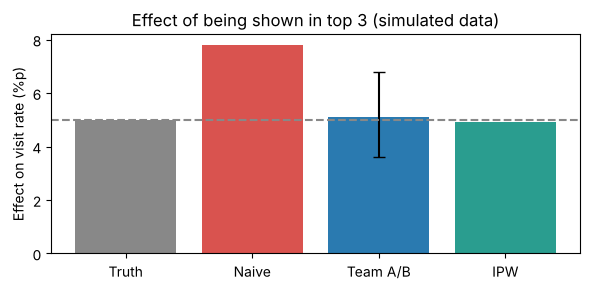

In [6]:
summary = pd.DataFrame({
    '방법': ['정답(우리가 정한 값)', '① 단순 비교', '② 팀 단위 A/B 실험', '③ IPW(성향점수)'],
    '추정 효과(%p)': [TRUE_EFFECT * 100, naive * 100, ab * 100, ipw * 100],
    '데이터': ['가상'] * 4,
}).round(1)
print(summary.to_string(index=False))

fig, ax = plt.subplots(figsize=(6, 3))
labels = ['Truth', 'Naive', 'Team A/B', 'IPW']
ax.bar(labels, summary['추정 효과(%p)'], color=['#888888', '#d9534f', '#2a7ab0', '#2a9d8f'])
ax.errorbar(2, ab * 100, yerr=[[ab * 100 - ab_lo * 100], [ab_hi * 100 - ab * 100]], color='black', capsize=4)
ax.axhline(TRUE_EFFECT * 100, ls='--', color='#888888')
ax.set_ylabel('Effect on visit rate (%p)')
ax.set_title('Effect of being shown in top 3 (simulated data)')
plt.tight_layout()
os.makedirs('outputs', exist_ok=True)
plt.savefig('outputs/05_causal_result.png', dpi=150)
summary.to_csv('outputs/05_causal_result.csv', index=False, encoding='utf-8-sig')
plt.show()

## 6. 정리 (보고서에 쓸 문장)
- **단순 비교는 추천 효과를 부풀린다.** 위쪽에 뜨는 식당이 원래 별점이 높고 가까워서(혼란변수) 그 효과가 섞이기 때문이다.
- **팀 단위 A/B 실험이 정답에 가장 가깝다.** 순서를 무작위로 섞으면 혼란변수가 양쪽에 고르게 나뉜다. 팀원끼리 같이 다니므로(간섭) 팀 단위로 나누고, 오차도 팀 단위로 계산했다. 다만 팀 수가 적으면 범위가 넓어지므로, 실제로 하면 팀을 충분히(이 예시는 20팀) 나눠야 한다.
- **IPW는 실험을 못 할 때의 대안이다.** 혼란변수를 다 알고 있으면 정답에 가까워지지만, 모르는 혼란변수(예: 그날 날씨, 팀장 취향)가 있으면 틀릴 수 있다.
- **우리 사이트에 적용:** 사이트가 남기는 `impressions.csv`(노출 기록)와 리뷰(방문) 기록이 있으면 같은 분석을 실제 데이터로 할 수 있다. 실험을 한다면 일부 팀에만 순서를 섞어 보여 주는 방식(클러스터 실험)이 맞다.
- 이 노트북의 직원·방문 데이터는 모두 **가상**이다.